# Football goals: attack and defence strengths

Each team has an **attack** and a **defence** strength. The number of goals a
team scores in a match depends on its attack, on the opponent's defence and on
whether it plays at home. This notebook fits that model to a season of match
scores, reads the estimates with their standard errors, and checks the fit.

The functions used here are those of
[`docs/examples/football_goals.py`](../examples/football_goals.py).

## 1. Theory

### Model

A match $m$ between home team $i$ and away team $j$ gives two observations, one
per side. For the side of team $a$ attacking against team $d$, the goals are
Poisson with a log-linear rate:

$$
Y \sim \mathrm{Poisson}(\lambda), \qquad
\log \lambda = \alpha_a - \delta_d + \eta\,\left(v - \tfrac12\right),
$$

where $\alpha$ is the attack, $\delta$ the defence (higher is better: it lowers
the opponent's rate), $\eta$ the home advantage and $v = 1$ for the home side,
$0$ for the away side. The home side scores $e^{\eta/2}$ times more than at a
neutral venue, the away side $e^{-\eta/2}$ times less.

### Likelihood

With $\eta_k = \log\lambda_k$ the linear predictor of observation $k$:

$$
\ell(\theta) = \sum_k \left( y_k\,\eta_k - e^{\eta_k} - \log y_k! \right),
\qquad
\nabla \ell = \sum_k (y_k - \lambda_k)\,\nabla\eta_k,
\qquad
\nabla^2 \ell = -\sum_k \lambda_k\,\nabla\eta_k \nabla\eta_k^\top .
$$

`maxlike` computes these derivatives exactly (first and second order) and
maximises $\ell$ with Newton's method. Each observation touches one attack and
one defence entry, so the Hessian is sparse; `Take` gathers the entries of
each observation without building a team $\times$ team grid.

### Identification

Adding the same constant $c$ to every $\alpha$ and every $\delta$ leaves every
rate unchanged: the likelihood is flat in that direction. One linear constraint
removes it,

$$
\textstyle\sum_a \alpha_a + \sum_d \delta_d = 0 .
$$

The optimiser solves the constrained problem through the bordered (KKT) Newton
system, and the standard errors come from the inverse of the same bordered
Hessian at the optimum, $\widehat{\mathrm{cov}}(\hat\theta) = -\left[\nabla^2\ell\right]^{-1}$ restricted to the
free parameters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson

import plot_style as ps
from plot_style import BLUE, ORANGE, TEXT_2
import football_goals as ex

ps.apply()

## 2. Data

One row per match: home team, away team and the goals of each.

In [2]:
matches = ex.load()
print(len(matches), "matches,", matches["home"].nunique(), "teams")
matches.head()

612 matches, 20 teams


,home,away,home_goals,away_goals
0,Team 00,Team 11,1,2
1,Team 01,Team 09,3,3
2,Team 02,Team 15,3,0
3,Team 03,Team 14,4,0
4,Team 04,Team 12,0,2


mean goals: home 1.45, away 1.10


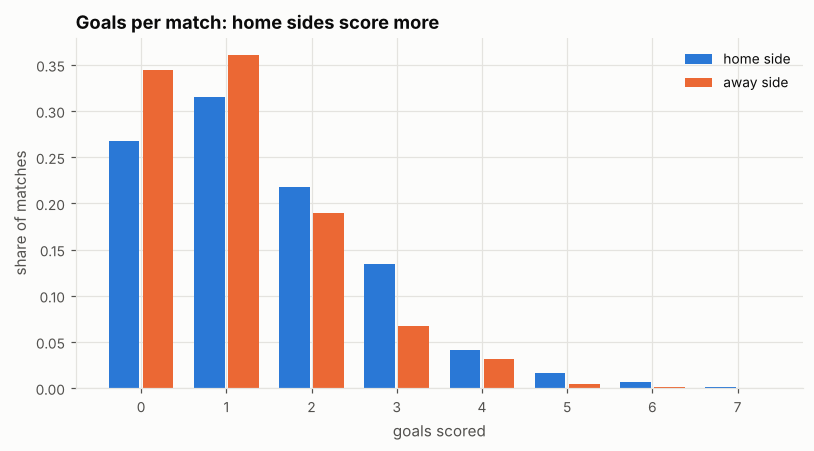

In [3]:
goals = np.arange(0, 8)
home_freq = matches["home_goals"].value_counts().reindex(goals, fill_value=0)
away_freq = matches["away_goals"].value_counts().reindex(goals, fill_value=0)

fig, ax = plt.subplots()
w = 0.4
ax.bar(goals - w / 2, home_freq / len(matches), w - 0.04, color=BLUE, label="home side")
ax.bar(goals + w / 2, away_freq / len(matches), w - 0.04, color=ORANGE, label="away side")
ax.set_xticks(goals)
ps.finish(ax, "Goals per match: home sides score more", "goals scored", "share of matches", legend=True)
print("mean goals: home %.2f, away %.2f" % (matches["home_goals"].mean(), matches["away_goals"].mean()))

## 3. Model and its graph

`fit` builds the linear predictor as a `Sum` of three terms: the attack of the
attacking team, minus the defence of the defending team, and the venue term.
The graph shows how the parameters flow into the likelihood, and the
identification constraint (dashed).

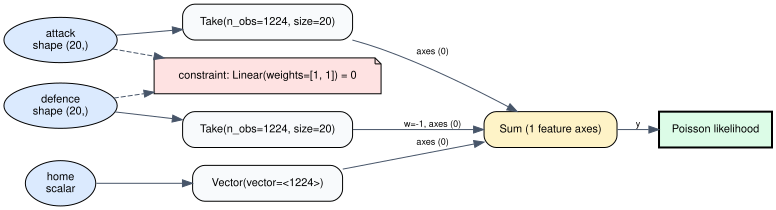

In [4]:
mle, teams = ex.fit(matches)
mle.graph()

## 4. Estimates

`summary()` gives one row per parameter entry: estimate, standard error, $z$,
p-value and 95% confidence interval. Log scale: an attack 0.2 higher means
$e^{0.2} \approx 1.22$ times more goals.

In [5]:
s = mle.summary()
s.loc[["home"]].round(4)

,,estimate,std_error,z,p_value,ci_95%_lower,ci_95%_upper,fixed
param,label,,,,,,,
home,,0.275,0.0511,5.3776,0.0,0.1748,0.3752,False


In [6]:
table = pd.DataFrame({
    "attack": s.loc["attack", "estimate"],
    "attack_se": s.loc["attack", "std_error"],
    "defence": s.loc["defence", "estimate"],
    "defence_se": s.loc["defence", "std_error"],
})
table["strength"] = table["attack"] + table["defence"]
table.sort_values("strength", ascending=False).round(3)

,attack,attack_se,defence,defence_se,strength
label,,,,,
Team 03,0.730,0.079,0.634,0.155,1.365
Team 02,0.588,0.085,0.446,0.140,1.034
Team 11,0.657,0.082,0.288,0.130,0.945
Team 06,0.329,0.096,0.097,0.117,0.426
Team 15,0.243,0.101,-0.156,0.103,0.087
Team 09,0.125,0.107,-0.046,0.108,0.079
Team 14,0.013,0.113,-0.040,0.108,-0.027
Team 08,0.002,0.114,-0.087,0.106,-0.084
Team 18,-0.053,0.166,-0.043,0.151,-0.097


Each team as a point: attack on the horizontal axis, defence on the vertical
axis, with 95% intervals. The best teams sit top right. The intervals are wide:
a season of 30 matches per team pins down a strength to about $\pm 0.2$.

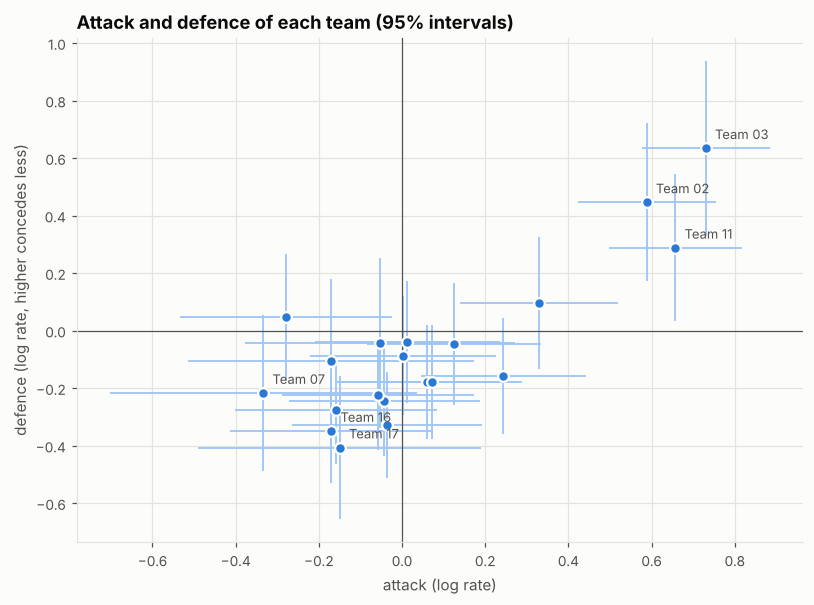

In [7]:
q = 1.96
fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.errorbar(table["attack"], table["defence"],
            xerr=q * table["attack_se"], yerr=q * table["defence_se"],
            fmt="o", color=BLUE, ecolor="#9ec5f4", elinewidth=1.2, markersize=7,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5)
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.axvline(0, color=TEXT_2, lw=0.8)
# label the three strongest and the three weakest teams only
ranked = table["strength"].sort_values()
for team in list(ranked.index[:3]) + list(ranked.index[-3:]):
    ax.annotate(team, (table.loc[team, "attack"], table.loc[team, "defence"]),
                xytext=(6, 6), textcoords="offset points", fontsize=8.5, color=TEXT_2)
ps.finish(ax, "Attack and defence of each team (95% intervals)",
          "attack (log rate)", "defence (log rate, higher concedes less)")

## 5. Predictions

`predict(model, se=True)` evaluates any function of the parameters at the
estimates, with delta-method standard errors
$\mathrm{se}(f) = \sqrt{J\,\widehat{\mathrm{cov}}\,J^\top}$, $J = \partial f/\partial\theta$.
Here: the expected goals of both sides of a match between the strongest and
the weakest team.

In [8]:
best, worst = table["strength"].idxmax(), table["strength"].idxmin()
value, se = ex.expected_goals(mle, teams, best, worst)
pd.DataFrame({"expected goals": value, "std_error": se},
             index=[best + " (home)", worst + " (away)"]).round(3)

,expected goals,std_error
Team 03 (home),3.576,0.540
Team 17 (away),0.398,0.095


## 6. Validation

**Goal distribution.** The fitted model is a mixture of Poisson
distributions, one per observation. Its marginal distribution of goals should
match the observed one.

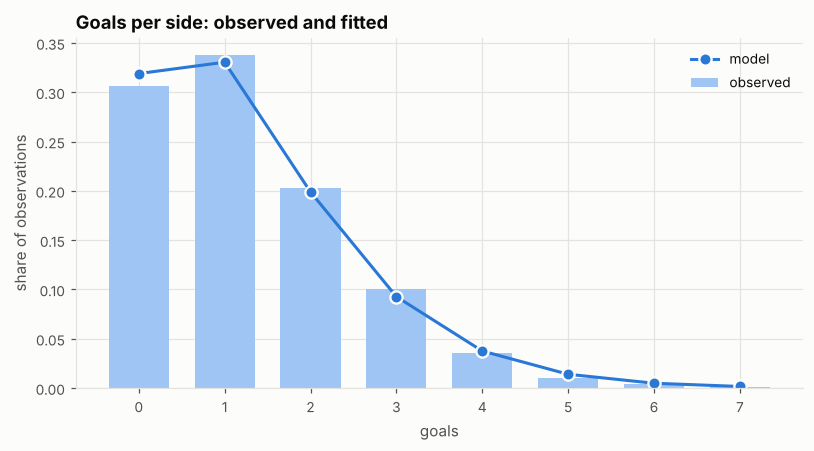

In [9]:
log_rate = mle.predict()                     # log lambda of each observation
lam = np.exp(log_rate)
y = np.concatenate([matches["home_goals"], matches["away_goals"]])
observed = np.bincount(y, minlength=8)[:8] / y.size
fitted = poisson.pmf(goals[:, None], lam[None, :]).mean(1)

fig, ax = plt.subplots()
ax.bar(goals, observed, 0.7, color="#9ec5f4", label="observed")
ax.plot(goals, fitted, "o-", color=BLUE, markersize=8, label="model",
        markeredgecolor="#fcfcfb", markeredgewidth=1.5)
ax.set_xticks(goals)
ps.finish(ax, "Goals per side: observed and fitted", "goals", "share of observations", legend=True)

**Calibration.** Group the observations by fitted rate and compare the mean
fitted rate with the mean number of goals in each group, with a 95% interval
for the observed mean. Points on the diagonal mean the rates are right on
average, across the whole range.

**Dispersion.** For a Poisson model the Pearson statistic
$\sum_k (y_k - \lambda_k)^2/\lambda_k$ divided by its degrees of freedom should
be close to 1; well above 1 would call for a negative binomial
(`maxlike.NegativeBinomial`).

Pearson dispersion: 0.946


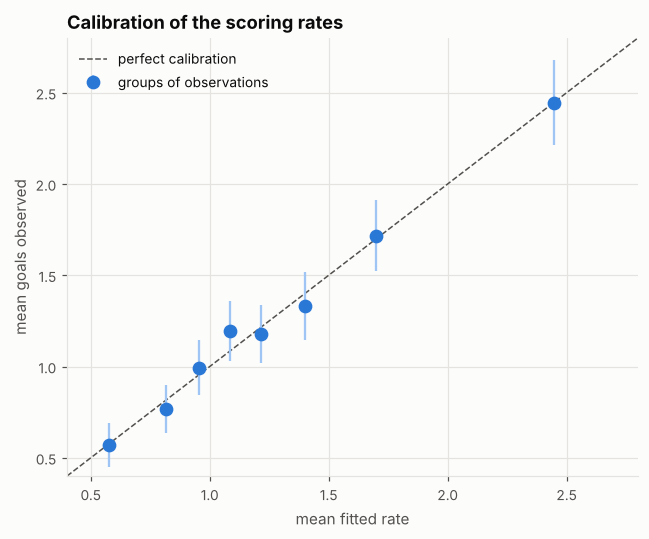

In [10]:
bins = pd.qcut(lam, 8)
g = pd.DataFrame({"lam": lam, "y": y}).groupby(bins, observed=True)
mean_lam, mean_y = g["lam"].mean(), g["y"].mean()
half = 1.96 * g["y"].std() / np.sqrt(g["y"].count())

fig, ax = plt.subplots(figsize=(6, 5))
lim = [0.4, 2.8]
ax.plot(lim, lim, color=TEXT_2, lw=1, ls="--", label="perfect calibration")
ax.errorbar(mean_lam, mean_y, yerr=half, fmt="o", color=BLUE, ecolor="#9ec5f4",
            markersize=8, elinewidth=1.5, label="groups of observations")
ax.set_xlim(lim); ax.set_ylim(lim)
ps.finish(ax, "Calibration of the scoring rates", "mean fitted rate", "mean goals observed", legend=True)

n_free = sum(int(p.count()) for p in mle.params) - 1     # one constraint
pearson = ((y - lam) ** 2 / lam).sum() / (y.size - n_free)
print("Pearson dispersion: %.3f" % pearson)